In [5]:
# CELL 0: NOTEBOOK PATH SETUP
# What this cell does:
#   - Adds the project root folder to Python's import path so that, from
#     Phase 2 onward, this notebook can import code from the src/ folder
#     (e.g. "from src.signals.impairments import add_awgn").
#   - Turns on autoreload, so when you edit a .py file in src/ the notebook
#     picks up the change automatically without restarting the kernel.
#   - Safe to run now even though src/ is still empty.

import sys
from pathlib import Path

# The notebook lives in rf-anomaly/notebooks/, so the project root is one level up
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

%load_ext autoreload
%autoreload 2

print("Project root:", project_root)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Project root: c:\Users\blbon\Desktop\MyWorkspace\FYP\personal projects\rf-anomaly


In [2]:
# CELL 1: SETUP
# What this cell does:
#   - Imports the libraries we'll use throughout Phase 1 (NumPy for math,
#     SciPy for signal tools, Matplotlib for plots).
#   - Fixes the random seed so your noise and results are reproducible.
#   - Sets default plot size so figures are readable.
#   - Prints library versions so we can debug quickly if something breaks.

import numpy as np
import scipy
from scipy import signal
import matplotlib.pyplot as plt

# Reproducibility: same seed -> same "random" noise every run
rng = np.random.default_rng(seed=42)

# Make plots larger and cleaner by default
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)

NumPy: 2.5.4
SciPy: 1.18.1


In [3]:
# CELL 2: GENERATE A COMPLEX TONE
# What this cell does:
#   - Defines the sampling rate (fs) and signal duration.
#   - Builds a time axis t = n / fs.
#   - Creates a complex exponential x[n] = exp(j*2*pi*f0*t).
#     Its real part is the I (in-phase) component = cos(2*pi*f0*t)
#     Its imaginary part is the Q (quadrature) component = sin(2*pi*f0*t)
#   - A complex tone at +f0 has energy ONLY at +f0 in the spectrum
#     (a real cosine would show up at both +f0 and -f0). This is why
#     RF/SDR systems use complex (I/Q) samples.
#   - Prints basic facts so you can check them against your expectations.

fs = 1_000_000          # sampling rate: 1 MHz (1 million samples/second)
duration = 0.01         # 10 milliseconds of signal
f0 = 100_000            # tone frequency: 100 kHz

N = int(fs * duration)  # total number of samples
t = np.arange(N) / fs   # time axis in seconds

x = np.exp(1j * 2 * np.pi * f0 * t)   # complex tone (I + jQ)

print("Number of samples:", N)
print("dtype:", x.dtype)
print("First 5 samples:", x[:5])
print("Average power |x|^2:", np.mean(np.abs(x) ** 2))
print("Nyquist limit (fs/2):", fs / 2, "Hz")

Number of samples: 10000
dtype: complex128
First 5 samples: [ 1.        +0.j          0.80901699+0.58778525j  0.30901699+0.95105652j
 -0.30901699+0.95105652j -0.80901699+0.58778525j]
Average power |x|^2: 1.0
Nyquist limit (fs/2): 500000.0 Hz


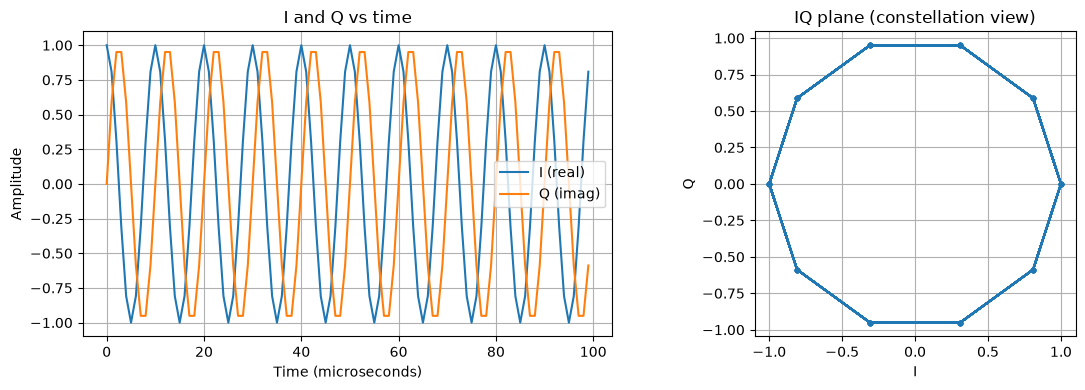

In [4]:
# CELL 3: VISUALISE I/Q IN TIME DOMAIN
# What this cell does:
#   - Plots only the first 100 microseconds so individual cycles are visible.
#   - Left plot: I(t) = real part and Q(t) = imaginary part vs time.
#     You should see two sinusoids 90 degrees apart (cos and sin).
#   - Right plot: I vs Q (the "IQ plane"). A pure complex tone has constant
#     magnitude and rotating phase, so it traces a perfect circle.
#   - Expected: period = 1/f0 = 10 microseconds, so about 10 cycles in the
#     left plot, and a unit circle on the right.

n_show = 100  # number of samples to plot (100 samples = 100 microseconds)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Left: time-domain I and Q
ax[0].plot(t[:n_show] * 1e6, x[:n_show].real, label="I (real)")
ax[0].plot(t[:n_show] * 1e6, x[:n_show].imag, label="Q (imag)")
ax[0].set_xlabel("Time (microseconds)")
ax[0].set_ylabel("Amplitude")
ax[0].set_title("I and Q vs time")
ax[0].legend()

# Right: IQ plane
ax[1].plot(x[:n_show].real, x[:n_show].imag, ".-")
ax[1].set_xlabel("I")
ax[1].set_ylabel("Q")
ax[1].set_title("IQ plane (constellation view)")
ax[1].set_aspect("equal")

plt.tight_layout()
plt.show()

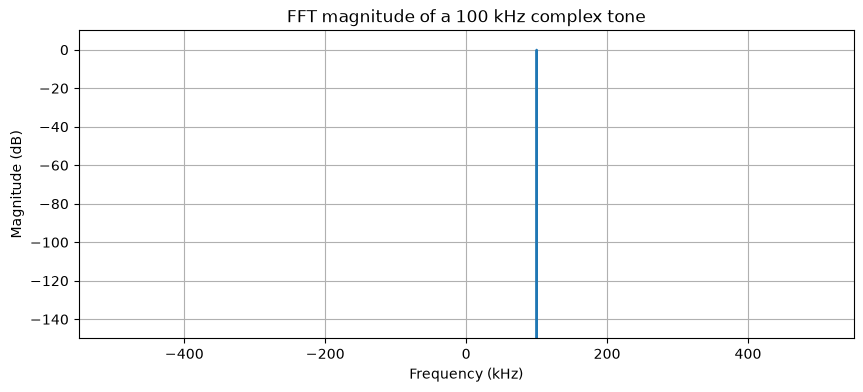

Bin spacing (Hz): 100.0
Peak frequency (Hz): 100000.0
Peak magnitude (linear): 1.0
Peak magnitude (dB): 8.686661818707667e-12
Median level away from peak (dB): -239.9938655001819


In [6]:
# CELL 4: FFT OF THE COMPLEX TONE
# What this cell does:
#   - Computes the N-point FFT of x and divides by N so a unit-amplitude
#     tone shows a peak of magnitude 1.0 (0 dB).
#   - np.fft.fftshift reorders the output so frequencies run from
#     -fs/2 to +fs/2 (negative frequencies on the left), the normal view
#     for complex I/Q signals.
#   - Builds the matching frequency axis with np.fft.fftfreq.
#   - Plots the magnitude in dB (20*log10) and prints the detected peak.
#   - Expected: ONE peak at +100 kHz and nothing at -100 kHz, because a
#     complex tone has only one frequency. Bin spacing is fs/N = 100 Hz,
#     and f0 = 1000 bins exactly, so the tone lands exactly on a bin.

X = np.fft.fftshift(np.fft.fft(x)) / N
freqs = np.fft.fftshift(np.fft.fftfreq(N, d=1 / fs))
mag_db = 20 * np.log10(np.abs(X) + 1e-12)   # tiny constant avoids log10(0)

peak_idx = np.argmax(np.abs(X))

plt.figure()
plt.plot(freqs / 1e3, mag_db)
plt.xlabel("Frequency (kHz)")
plt.ylabel("Magnitude (dB)")
plt.title("FFT magnitude of a 100 kHz complex tone")
plt.ylim(-150, 10)
plt.show()

print("Bin spacing (Hz):", fs / N)
print("Peak frequency (Hz):", freqs[peak_idx])
print("Peak magnitude (linear):", np.abs(X[peak_idx]))
print("Peak magnitude (dB):", mag_db[peak_idx])
print("Median level away from peak (dB):", np.median(mag_db))

Rectangular  peak:   -3.92 dB | level 300 kHz away:   -78.16 dB
Hann         peak:   -1.42 dB | level 300 kHz away:  -218.44 dB
Blackman     peak:   -1.10 dB | level 300 kHz away:  -224.89 dB


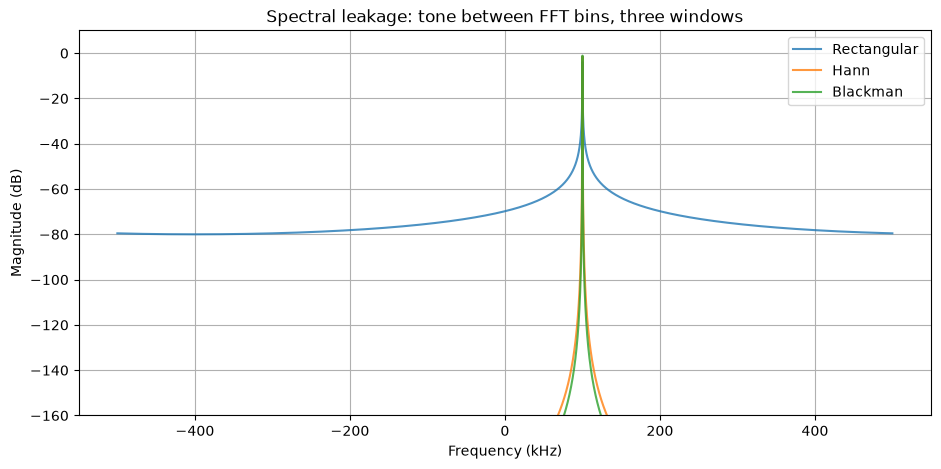

In [7]:
# CELL 5: SPECTRAL LEAKAGE AND WINDOWS
# What this cell does:
#   - Creates a tone at 100,050 Hz. This is 1000.5 bins, so it falls
#     BETWEEN two FFT bins, the worst case for leakage. Real signals are
#     almost never exactly on a bin, so this is the realistic case.
#   - Computes the spectrum with three windows applied before the FFT:
#       rectangular (no window), Hann, and Blackman.
#   - Divides by sum(window) so peaks are comparable across windows.
#   - Overlays the three spectra. Expected: rectangular has high
#     "skirts" that decay slowly; Hann and Blackman push leakage far
#     lower, at the price of a wider main peak.
#   - Prints the peak level, and the level 300 kHz away from the tone,
#     for each window so you can compare numerically.

f_off = 100_050                           # between bins
x_off = np.exp(1j * 2 * np.pi * f_off * t)

windows = {
    "Rectangular": np.ones(N),
    "Hann": signal.get_window("hann", N),
    "Blackman": signal.get_window("blackman", N),
}

plt.figure(figsize=(11, 5))
far_idx = np.argmin(np.abs(freqs - (f_off + 300_000)))   # bin ~300 kHz away

for name, w in windows.items():
    Xw = np.fft.fftshift(np.fft.fft(x_off * w)) / np.sum(w)
    Xw_db = 20 * np.log10(np.abs(Xw) + 1e-12)
    plt.plot(freqs / 1e3, Xw_db, label=name, alpha=0.8)
    print(f"{name:12s} peak: {Xw_db.max():7.2f} dB | "
          f"level 300 kHz away: {Xw_db[far_idx]:8.2f} dB")

plt.xlabel("Frequency (kHz)")
plt.ylabel("Magnitude (dB)")
plt.title("Spectral leakage: tone between FFT bins, three windows")
plt.ylim(-160, 10)
plt.legend()
plt.show()

Rectangular  peak:   0.00 dB | 3 dB width:   87.5 Hz
Hann         peak:   0.00 dB | 3 dB width:  137.5 Hz
Blackman     peak:   0.00 dB | 3 dB width:  162.5 Hz


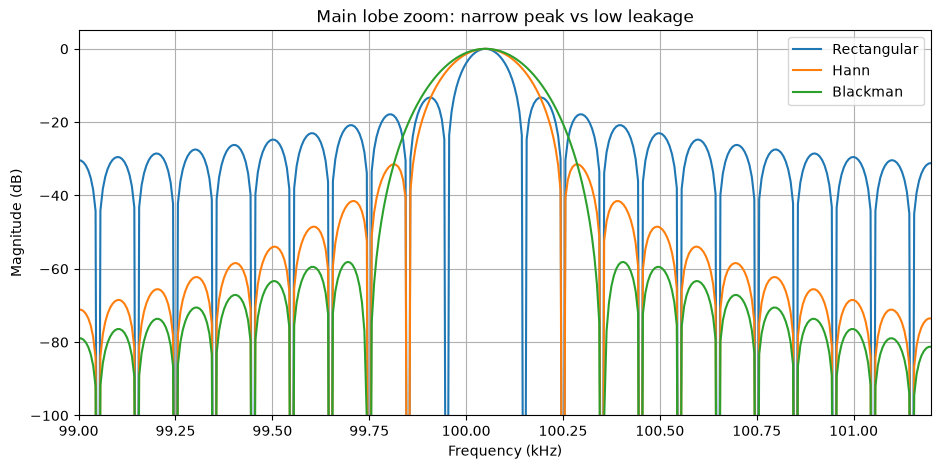

In [8]:
# CELL 6: ZOOM ON THE MAIN LOBE (WIDTH vs LEAKAGE TRADE-OFF)
# What this cell does:
#   - Zero-pads the FFT to 16*N points. Zero-padding does not add new
#     information; it interpolates the spectrum so you can see the true
#     smooth shape of each window's main peak.
#   - Plots only 99 to 101.2 kHz, so the main lobe fills the plot.
#   - Because the padded FFT samples the peak finely, each curve now peaks
#     near 0 dB. This confirms the earlier -3.92 dB was scalloping loss
#     from the coarse bin grid, not real signal loss.
#   - Prints the 3 dB bandwidth (width where the level is within 3 dB of the
#     peak) for each window.
#   - Expected approx: Rectangular ~89 Hz, Hann ~144 Hz, Blackman ~168 Hz.
#     (about 0.89, 1.44, 1.68 bins of 100 Hz)

nfft = 16 * N
fz = np.fft.fftshift(np.fft.fftfreq(nfft, d=1 / fs))

plt.figure(figsize=(11, 5))
for name, w in windows.items():
    Xw = np.fft.fftshift(np.fft.fft(x_off * w, n=nfft)) / np.sum(w)
    Xw_db = 20 * np.log10(np.abs(Xw) + 1e-12)
    plt.plot(fz / 1e3, Xw_db, label=name)

    inside = Xw_db >= (Xw_db.max() - 3)           # region within 3 dB of peak
    width = fz[inside].max() - fz[inside].min()
    print(f"{name:12s} peak: {Xw_db.max():6.2f} dB | 3 dB width: {width:6.1f} Hz")

plt.xlim(99.0, 101.2)
plt.ylim(-100, 5)
plt.xlabel("Frequency (kHz)")
plt.ylabel("Magnitude (dB)")
plt.title("Main lobe zoom: narrow peak vs low leakage")
plt.legend()
plt.show()

In [9]:
# CELL 7: ADD NOISE AT A TARGET SNR (THE MOST IMPORTANT FUNCTION)
# What this cell does:
#   - Defines add_awgn(x, snr_db, rng), which adds complex white Gaussian
#     noise so that  SNR = (signal power) / (noise power)  equals snr_db.
#   - Steps: measure signal power Ps = mean(|x|^2); compute the needed noise
#     power Pn = Ps / 10^(snr_db/10); generate complex noise where I and Q
#     each have variance Pn/2 (so total variance is Pn).
#   - Then TESTS the function: for several target SNRs it adds noise,
#     separates the noise (y - x), measures the real SNR, and prints the
#     error. Errors should be tiny (a few hundredths of a dB).
#   - We test it now because every later result depends on SNR being
#     exactly right.

def add_awgn(x, snr_db, rng):
    p_signal = np.mean(np.abs(x) ** 2)
    p_noise = p_signal / (10 ** (snr_db / 10))
    noise = np.sqrt(p_noise / 2) * (
        rng.standard_normal(x.shape) + 1j * rng.standard_normal(x.shape)
    )
    return x + noise

print(f"{'target SNR':>10s} | {'measured SNR':>12s} | {'error (dB)':>10s}")
for snr_target in [-10, -5, 0, 5, 10, 20]:
    y = add_awgn(x, snr_target, rng)
    noise_only = y - x
    snr_measured = 10 * np.log10(np.mean(np.abs(x) ** 2) / np.mean(np.abs(noise_only) ** 2))
    print(f"{snr_target:10d} | {snr_measured:12.3f} | {snr_measured - snr_target:10.3f}")

target SNR | measured SNR | error (dB)
       -10 |      -10.041 |     -0.041
        -5 |       -5.038 |     -0.038
         0 |        0.022 |      0.022
         5 |        4.959 |     -0.041
        10 |        9.938 |     -0.062
        20 |       19.966 |     -0.034


SNR   20 dB | peak:   0.01 dB | noise floor:  -59.94 dB | expected:  -60.00 dB
SNR    0 dB | peak:  -0.02 dB | noise floor:  -40.01 dB | expected:  -40.00 dB
SNR  -10 dB | peak:   0.26 dB | noise floor:  -30.02 dB | expected:  -30.00 dB


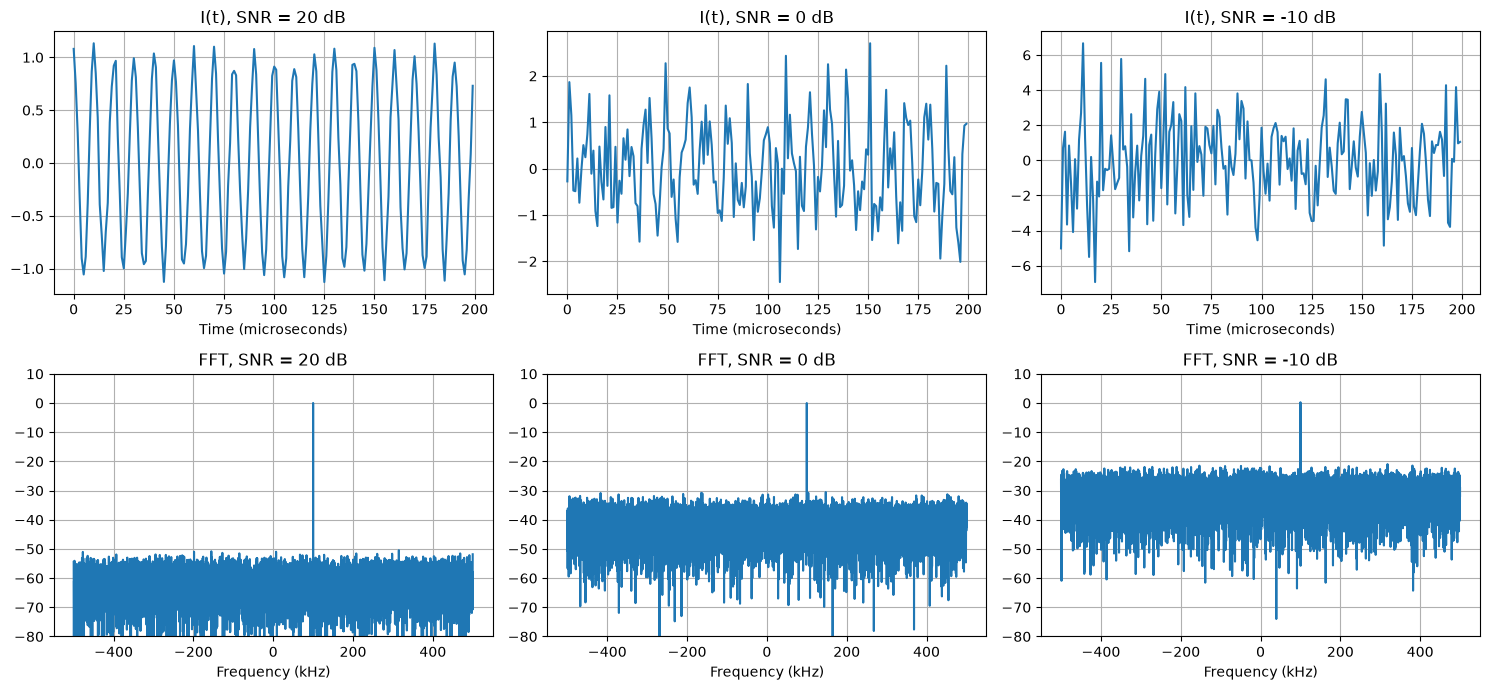

In [10]:
# CELL 8: WHAT NOISE DOES IN TIME vs FREQUENCY DOMAIN
# What this cell does:
#   - Adds noise at three SNRs (20 dB, 0 dB, -10 dB) to the 100 kHz tone.
#   - Top row: the real part (I) in time. At -10 dB the tone is invisible
#     by eye.
#   - Bottom row: the FFT magnitude in dB. The tone should still stand out.
#   - Why: the FFT concentrates the tone's energy into ONE bin, while noise
#     spreads over all N bins. This "processing gain" is 10*log10(N) = 40 dB
#     here.
#   - The printed noise floor is the average power of all bins except the
#     peak. Expected noise floor = -SNR - 10*log10(N) dB (relative to the
#     tone peak at 0 dB).

fig, ax = plt.subplots(2, 3, figsize=(15, 7))

for col, snr_db in enumerate([20, 0, -10]):
    y = add_awgn(x, snr_db, rng)

    # time domain (first 200 samples of I)
    ax[0, col].plot(t[:200] * 1e6, y[:200].real)
    ax[0, col].set_title(f"I(t), SNR = {snr_db} dB")
    ax[0, col].set_xlabel("Time (microseconds)")

    # frequency domain
    Y = np.fft.fftshift(np.fft.fft(y)) / N
    Y_db = 20 * np.log10(np.abs(Y) + 1e-12)
    ax[1, col].plot(freqs / 1e3, Y_db)
    ax[1, col].set_title(f"FFT, SNR = {snr_db} dB")
    ax[1, col].set_xlabel("Frequency (kHz)")
    ax[1, col].set_ylim(-80, 10)

    # numeric check of the noise floor
    p = np.abs(Y) ** 2
    pk = np.argmax(p)
    floor_db = 10 * np.log10(np.mean(np.delete(p, pk)))
    expected = -snr_db - 10 * np.log10(N)
    print(f"SNR {snr_db:4d} dB | peak: {Y_db[pk]:6.2f} dB | "
          f"noise floor: {floor_db:7.2f} dB | expected: {expected:7.2f} dB")

plt.tight_layout()
plt.show()

Periodogram bin:   100.0 Hz | peak above floor:  28.4 dB | floor spread: 5.60 dB
Welch       bin:   976.6 Hz | peak above floor:  17.5 dB | floor spread: 1.06 dB


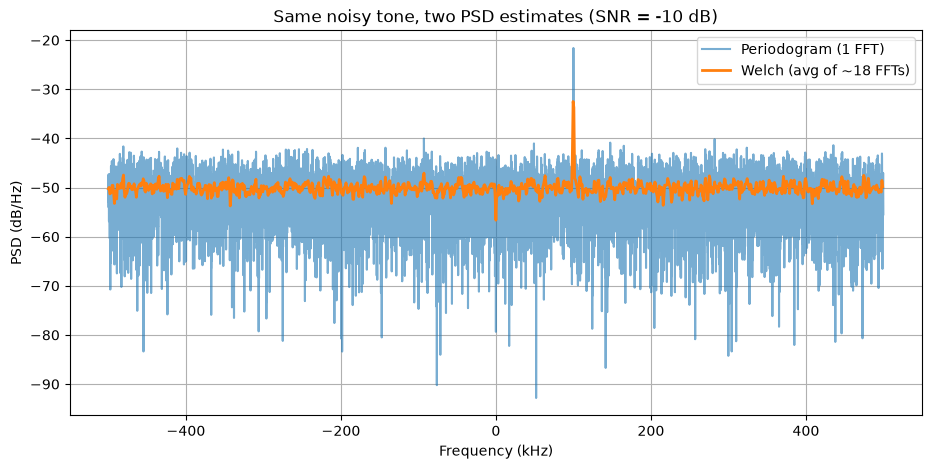

In [15]:
# CELL 9: PERIODOGRAM vs WELCH PSD
# What this cell does:
#   - Takes the 100 kHz tone at -10 dB SNR and estimates its power spectral
#     density (PSD, power per Hz) in two ways:
#       (a) periodogram: ONE Hann-windowed FFT of all 10,000 samples
#           (what you did in Cell 8)
#       (b) Welch: split the signal into 1024-sample segments with 50%
#           overlap, FFT each, and AVERAGE the power. Averaging ~18 noisy
#           spectra smooths the noise floor.
#   - fftshift is applied so frequencies run from -500 kHz to +500 kHz.
#   - Prints, for each method: bin width, how far the tone peak is above
#     the average noise floor, and the "spread" (std in dB) of the noise
#     floor bins. Spread measures how jagged the floor is.
#   - Expected approx: periodogram -> bin 100 Hz, peak ~28 dB above floor,
#     spread ~5.6 dB. Welch -> bin ~977 Hz, peak ~17-18 dB above floor,
#     spread ~1-1.5 dB.
#   - Trade-off: Welch gives a much smoother floor, but wider bins mean
#     the tone peak stands out less. Smooth vs sharp.

snr_db = -10
y = add_awgn(x, snr_db, rng)

f_p, P_p = signal.periodogram(y, fs=fs, window="hann",
                              return_onesided=False, scaling="density")
f_w, P_w = signal.welch(y, fs=fs, window="hann", nperseg=1024, noverlap=512,
                        return_onesided=False, scaling="density")

f_p, P_p = np.fft.fftshift(f_p), np.fft.fftshift(P_p)
f_w, P_w = np.fft.fftshift(f_w), np.fft.fftshift(P_w)

def summarize(name, f, P):
    away = np.abs(f - f0) > 20e3                    # bins far from the tone
    floor_db = 10 * np.log10(np.mean(P[away]))      # average noise floor
    peak_db = 10 * np.log10(P.max())
    spread_db = np.std(10 * np.log10(P[away]))
    print(f"{name:11s} bin: {f[1]-f[0]:7.1f} Hz | peak above floor: "
          f"{peak_db - floor_db:5.1f} dB | floor spread: {spread_db:4.2f} dB")

summarize("Periodogram", f_p, P_p)
summarize("Welch", f_w, P_w)

plt.figure(figsize=(11, 5))
plt.plot(f_p / 1e3, 10 * np.log10(P_p + 1e-20), alpha=0.6, label="Periodogram (1 FFT)")
plt.plot(f_w / 1e3, 10 * np.log10(P_w + 1e-20), lw=2, label="Welch (avg of ~18 FFTs)")
plt.xlabel("Frequency (kHz)")
plt.ylabel("PSD (dB/Hz)")
plt.title("Same noisy tone, two PSD estimates (SNR = -10 dB)")
plt.legend()
plt.show()

Spectrogram shape (freq bins, time slices): (256, 316)
Frequency resolution: 3906.2 Hz | window length: 256 us | hop: 64 us
Strongest frequency (time-averaged): 101.6 kHz


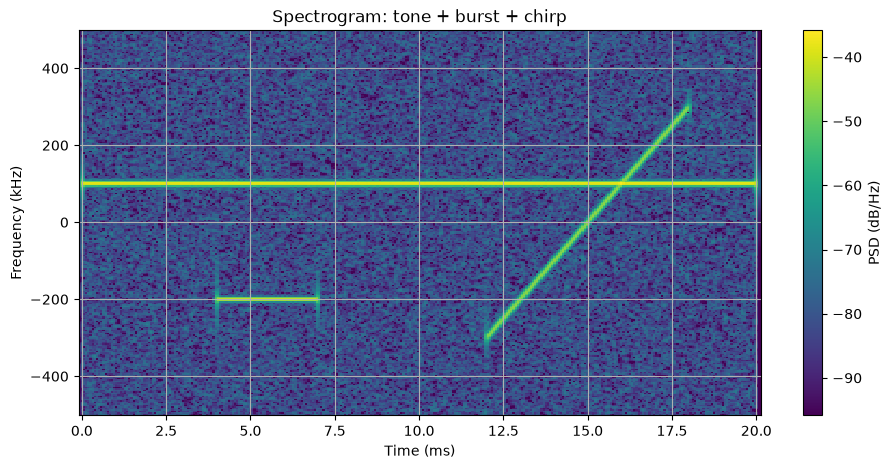

In [16]:
# CELL 10: A SIGNAL THAT CHANGES WITH TIME, AND ITS SPECTROGRAM
# What this cell does:
#   - Builds a 20 ms test signal with three components:
#       1) a constant tone at +100 kHz (always on, like a normal carrier)
#       2) a BURST: tone at -200 kHz, only between 4 ms and 7 ms
#       3) a CHIRP: sweeps linearly from -300 kHz to +300 kHz between
#          12 ms and 18 ms (so it crosses 0 Hz at 15 ms)
#     Then adds complex noise (power 0.01, i.e. -20 dB relative to the tone).
#   - Computes the spectrogram with scipy's ShortTimeFFT: slide a 256-sample
#     Hann window along the signal in steps of 64 samples, FFT each slice.
#   - Plots time (x) vs frequency (y) with colour = PSD in dB.
#   - Expected: a horizontal line at +100 kHz the whole time, a short
#     horizontal line at -200 kHz (4-7 ms), and a diagonal line (chirp).
#   - A single FFT of this signal could not tell WHEN each thing happened.
#     The spectrogram can, so it is the input to our anomaly detector.

dur2 = 0.02
N2 = int(fs * dur2)
t2 = np.arange(N2) / fs

sig = np.exp(1j * 2 * np.pi * 100e3 * t2)                       # constant tone

burst_mask = (t2 >= 4e-3) & (t2 < 7e-3)                         # burst: 4-7 ms
sig = sig + 0.7 * burst_mask * np.exp(1j * 2 * np.pi * (-200e3) * t2)

chirp_mask = (t2 >= 12e-3) & (t2 < 18e-3)                       # chirp: 12-18 ms
tc = t2 - 12e-3                                                 # time since chirp start
k_rate = 600e3 / 6e-3                                           # sweep rate (Hz/s)
chirp_phase = 2 * np.pi * (-300e3 * tc + 0.5 * k_rate * tc ** 2)
sig = sig + 0.5 * chirp_mask * np.exp(1j * chirp_phase)

noise_power = 0.01
noise = np.sqrt(noise_power / 2) * (rng.standard_normal(N2) + 1j * rng.standard_normal(N2))
sig_noisy = sig + noise

win_len, hop = 256, 64
SFT = signal.ShortTimeFFT(signal.get_window("hann", win_len), hop=hop, fs=fs,
                          fft_mode="centered", scale_to="psd")
Sx = SFT.spectrogram(sig_noisy)                # shape: (freq bins, time slices)
Sx_db = 10 * np.log10(Sx + 1e-20)
t_axis, f_axis = SFT.t(N2), SFT.f

print("Spectrogram shape (freq bins, time slices):", Sx.shape)
print(f"Frequency resolution: {fs / win_len:.1f} Hz | window length: {win_len / fs * 1e6:.0f} us "
      f"| hop: {hop / fs * 1e6:.0f} us")
mean_psd = Sx.mean(axis=1)
print(f"Strongest frequency (time-averaged): {f_axis[np.argmax(mean_psd)] / 1e3:.1f} kHz")

plt.figure(figsize=(11, 5))
plt.pcolormesh(t_axis * 1e3, f_axis / 1e3, Sx_db, shading="auto",
               vmin=Sx_db.max() - 60, vmax=Sx_db.max())
plt.colorbar(label="PSD (dB/Hz)")
plt.xlabel("Time (ms)")
plt.ylabel("Frequency (kHz)")
plt.title("Spectrogram: tone + burst + chirp")
plt.show()

window    64: freq resolution  15625.0 Hz | duration     64 us
window   256: freq resolution   3906.2 Hz | duration    256 us
window  1024: freq resolution    976.6 Hz | duration   1024 us


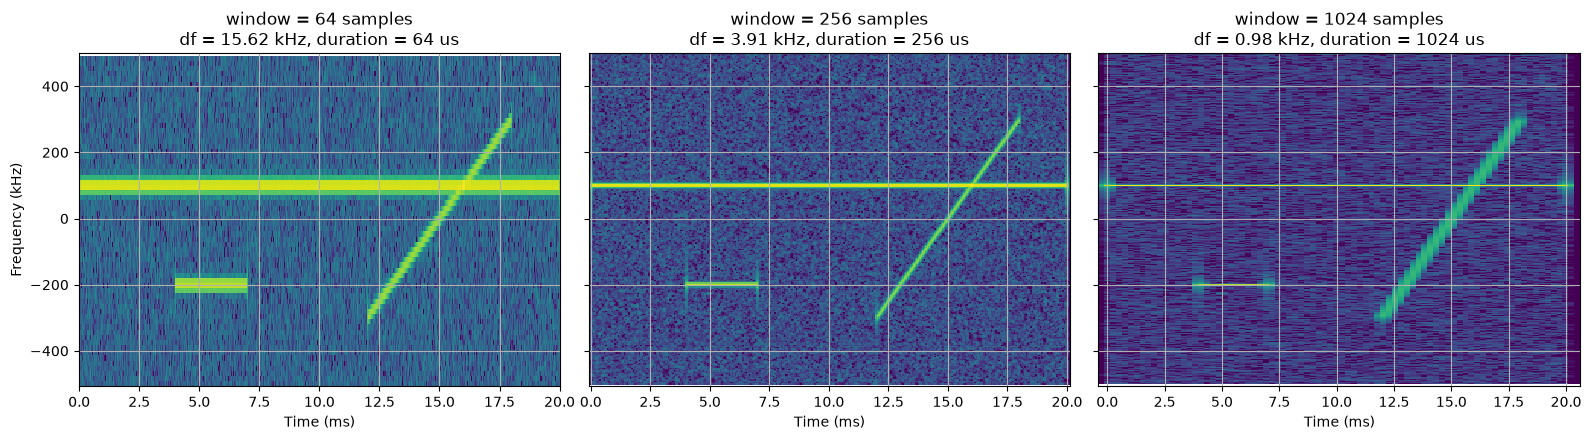

In [17]:
# CELL 11: THE TIME-FREQUENCY RESOLUTION TRADE-OFF
# What this cell does:
#   - Computes the spectrogram of the SAME signal with three window lengths:
#     64, 256 and 1024 samples (hop = window/4 each time).
#   - Short window: good time resolution (burst edges are sharp) but poor
#     frequency resolution (lines are thick).
#   - Long window: sharp thin frequency lines but poor time resolution
#     (burst edges and the chirp smear).
#   - You cannot get both. This trade-off (a form of the uncertainty
#     principle) is a key design choice when we build the anomaly detector.
#   - Prints each setting's frequency resolution (fs / window) and window
#     duration so you can relate them to what you see in the plots.

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for ax, wl in zip(axes, [64, 256, 1024]):
    SFT_i = signal.ShortTimeFFT(signal.get_window("hann", wl), hop=wl // 4, fs=fs,
                                fft_mode="centered", scale_to="psd")
    S_i = 10 * np.log10(SFT_i.spectrogram(sig_noisy) + 1e-20)
    ax.pcolormesh(SFT_i.t(N2) * 1e3, SFT_i.f / 1e3, S_i, shading="auto",
                  vmin=S_i.max() - 60, vmax=S_i.max())
    ax.set_title(f"window = {wl} samples\n"
                 f"df = {fs / wl / 1e3:.2f} kHz, duration = {wl / fs * 1e6:.0f} us")
    ax.set_xlabel("Time (ms)")
    print(f"window {wl:5d}: freq resolution {fs / wl:8.1f} Hz | duration {wl / fs * 1e6:6.0f} us")

axes[0].set_ylabel("Frequency (kHz)")
plt.tight_layout()
plt.show()

Threshold: 11.23 dB above the median background (p_fa = 0.0001)
Burst detected in 100.0% of its time slices
Chirp detected in 100.0% of its time slices
Flagged pixels in the tone band (normal): 16
Flagged pixels elsewhere: 128 (pure-noise expectation: 7.7 of 76832 pixels)


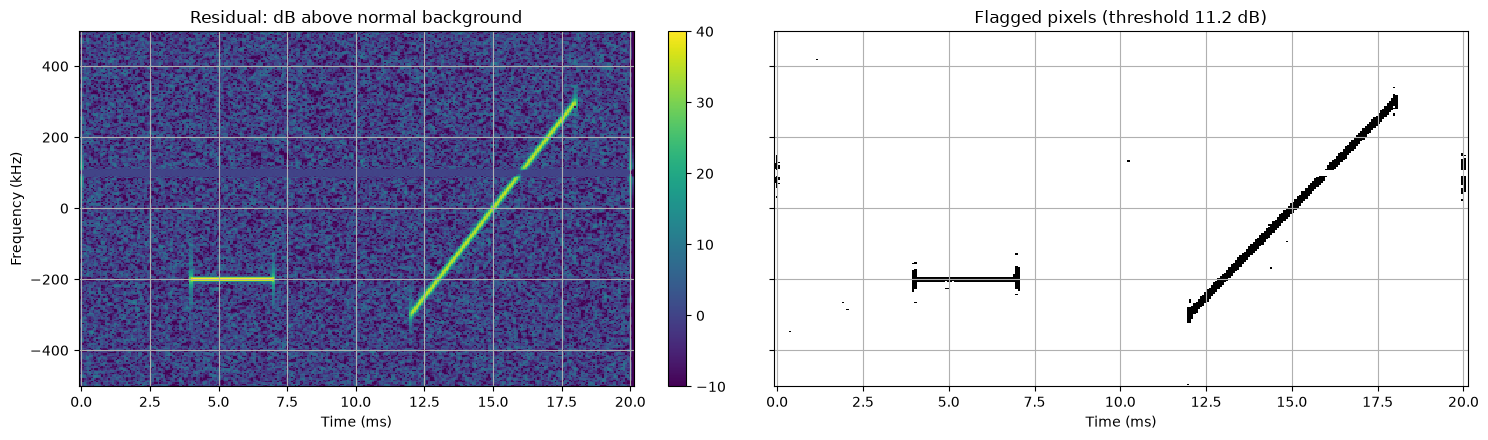

In [18]:
# CELL 12: A FIRST, NAIVE ANOMALY DETECTOR ON THE SPECTROGRAM
# What this cell does:
#   - Treats the time-MEDIAN of each frequency row of the spectrogram as the
#     "normal background" (tone + noise floor). Anything far above it is
#     flagged. A median is used because short-lived events don't move it.
#   - Chooses the threshold from THEORY, not by eye: noise-only spectrogram
#     power is exponentially distributed, so P(power > r * mean) = exp(-r).
#     For a target false-alarm probability p_fa per pixel, the threshold
#     relative to the MEDIAN (= 0.693 * mean) is  -ln(p_fa) / ln(2)
#     (converted to dB). This is "set the threshold at a fixed false-alarm
#     rate", the same idea as in our final evaluation.
#   - Builds ground-truth masks (where the burst and chirp really are, with
#     a small tolerance) so we can count how well it detects them.
#   - Reports: (a) fraction of burst time slices and chirp time slices where
#     at least one pixel fired, (b) flagged pixels OUTSIDE the true anomaly
#     and normal-tone regions, compared with the number expected from noise
#     alone (p_fa * number of pixels).
#   - Plots the residual (dB above background) and the flagged pixels.
#   - Needs variables from Cell 10: Sx_db, t_axis, f_axis.

p_fa = 1e-4                                    # target false alarms per pixel

bg_db = np.median(Sx_db, axis=1, keepdims=True)   # normal background per frequency
resid_db = Sx_db - bg_db                          # dB above normal
thr_db = 10 * np.log10(-np.log(p_fa) / np.log(2))
flagged = resid_db > thr_db

# Ground truth masks (shape: freq x time)
tt, ff = np.meshgrid(t_axis, f_axis)
tol_t = 0.2e-3                                    # time tolerance around edges
f_chirp = -300e3 + (600e3 / 6e-3) * (tt - 12e-3)  # chirp frequency vs time
in_burst = (tt >= 4e-3 - tol_t) & (tt <= 7e-3 + tol_t) & (np.abs(ff + 200e3) < 12e3)
in_chirp = (tt >= 12e-3 - tol_t) & (tt <= 18e-3 + tol_t) & (np.abs(ff - f_chirp) < 25e3)
near_tone = np.abs(ff - 100e3) < 15e3
elsewhere = ~(in_burst | in_chirp | near_tone)

# Per-time-slice detection (inner part of each event, away from edges)
cols_burst = (t_axis >= 4.1e-3) & (t_axis <= 6.9e-3)
cols_chirp = (t_axis >= 12.1e-3) & (t_axis <= 17.9e-3)
burst_hit = (flagged & in_burst)[:, cols_burst].any(axis=0).mean()
chirp_hit = (flagged & in_chirp)[:, cols_chirp].any(axis=0).mean()

print(f"Threshold: {thr_db:.2f} dB above the median background (p_fa = {p_fa})")
print(f"Burst detected in {burst_hit * 100:.1f}% of its time slices")
print(f"Chirp detected in {chirp_hit * 100:.1f}% of its time slices")
print(f"Flagged pixels in the tone band (normal): {flagged[near_tone & ~in_chirp].sum()}")
print(f"Flagged pixels elsewhere: {flagged[elsewhere].sum()} "
      f"(pure-noise expectation: {p_fa * elsewhere.sum():.1f} of {elsewhere.sum()} pixels)")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
im0 = ax[0].pcolormesh(t_axis * 1e3, f_axis / 1e3, resid_db, shading="auto", vmin=-10, vmax=40)
ax[0].set_title("Residual: dB above normal background")
plt.colorbar(im0, ax=ax[0])
ax[1].pcolormesh(t_axis * 1e3, f_axis / 1e3, flagged.astype(float), shading="auto", cmap="gray_r")
ax[1].set_title(f"Flagged pixels (threshold {thr_db:.1f} dB)")
for a in ax:
    a.set_xlabel("Time (ms)")
ax[0].set_ylabel("Frequency (kHz)")
plt.tight_layout()
plt.show()

In [19]:
# CELL 13: IMPORT FROM src/ AND CHECK IT MATCHES THE NOTEBOOK VERSION
# What this cell does:
#   - Imports add_awgn from src/signals/impairments.py (this works because
#     Cell 0 added the project root to the import path).
#   - Runs the notebook's add_awgn (Cell 7) and the src version with two
#     generators that have the SAME seed. Same code + same seed -> identical
#     numbers, so np.array_equal should print True.
#   - Also shifts the tone with apply_freq_offset and prints where the FFT
#     peak lands (expected 150000 Hz).
#   - If the import fails, the error text tells us whether it is a path
#     problem (Cell 0 not run / wrong folder) or a missing __init__.py.

from src.signals.impairments import add_awgn as add_awgn_src, apply_freq_offset

a = add_awgn(x, 5, np.random.default_rng(0))
b = add_awgn_src(x, 5, np.random.default_rng(0))
print("Notebook and src versions identical:", np.array_equal(a, b))

x_shift = apply_freq_offset(x, 50_000, fs)
X_shift = np.fft.fftshift(np.fft.fft(x_shift))
print("Peak after +50 kHz offset (Hz):", freqs[np.argmax(np.abs(X_shift))])

Notebook and src versions identical: True
Peak after +50 kHz offset (Hz): 150000.0


In [20]:
# CELL 14: DIAGNOSE THE EXTRA FALSE ALARMS
# What this cell does:
#   - Splits the pixels that fired "elsewhere" (not on the tone, burst or
#     chirp) into three groups:
#       1) recording edges: first/last 0.3 ms, where the window runs off
#          the signal
#       2) event splatter: within 0.3 ms of the start/stop of the burst or
#          chirp (4, 7, 12, 18 ms)
#       3) clean noise region: everything else
#   - Prints, for each group, the number of pixels, how many fired, and the
#     firing rate. For the clean group we compare with the target p_fa.
#   - Also splits the tone-band flags into edge vs non-edge.
#   - Expected: groups 1 and 2 account for most flags; the clean region fires
#     at a rate near p_fa (within a few times, because the background is
#     estimated from limited data).
#   - Needs variables from Cell 12: flagged, tt, ff, in_chirp, near_tone,
#     elsewhere, p_fa.

edge_time = (tt < 0.3e-3) | (tt > 20e-3 - 0.3e-3)

near_event_edge = np.zeros_like(tt, dtype=bool)
for e in [4e-3, 7e-3, 12e-3, 18e-3]:
    near_event_edge |= np.abs(tt - e) < 0.3e-3

groups = {
    "recording edges": elsewhere & edge_time,
    "event splatter": elsewhere & ~edge_time & near_event_edge,
    "clean noise region": elsewhere & ~edge_time & ~near_event_edge,
}

print(f"{'group':22s} | {'pixels':>7s} | {'fired':>6s} | {'rate':>10s}")
for name, mask in groups.items():
    n_pix, n_fired = mask.sum(), flagged[mask].sum()
    print(f"{name:22s} | {n_pix:7d} | {n_fired:6d} | {n_fired / n_pix:10.2e}")

print(f"Target false-alarm rate (p_fa): {p_fa:.1e}")

tone_zone = near_tone & ~in_chirp
print("Tone band fired at recording edges:", flagged[tone_zone & edge_time].sum())
print("Tone band fired elsewhere in time :", flagged[tone_zone & ~edge_time].sum())

group                  |  pixels |  fired |       rate
recording edges        |    3224 |     64 |   1.99e-02
event splatter         |    9370 |     55 |   5.87e-03
clean noise region     |   64238 |      9 |   1.40e-04
Target false-alarm rate (p_fa): 1.0e-04
Tone band fired at recording edges: 16
Tone band fired elsewhere in time : 0
